In [1]:
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch
from statsmodels.graphics.tsaplots import plot_acf


### Hay que diferenciar una serie cuando no es estacionaria y quieres convertirla en estacionaria para poder modelarla correctamente.

- Diaria	Anual	365 (o 365.25)
- Diaria	Semanal	7
- Mensual	Anual	12
- Trimestral	Anual	4
- Horaria	Diaria	24
- Horaria	Semanal	168

1. Diagrama de autocorrelacion- mirar componente estacional. En caso de tener componente estacional (sesional descompose) y nos quedamos con residuo
2. Analizar estacionariedad. Debe de tener media constante, para ello miramos ADF y KPSS. Varianza kte miramos con test de Engle. Autocovarianza kte lo sabemos porque ya no tenemos un patron



# Test Unitarios vs Test de heterocedasticidad
Para cada una de las series:
1. Realizar la descomposición de la serie y extraer el residuo.
2. Comprobad la estacionariedad mediante los test de raiz unitaria.
3. Comprobar la presencia de heterocedasticidad mediante el test de Engle.

### 1. Serie aditiva

In [2]:
series_ad = pd.read_csv('daily-min-temperatures.csv', header=0, parse_dates=['Date'], index_col='Date')
series_ad.head()

,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


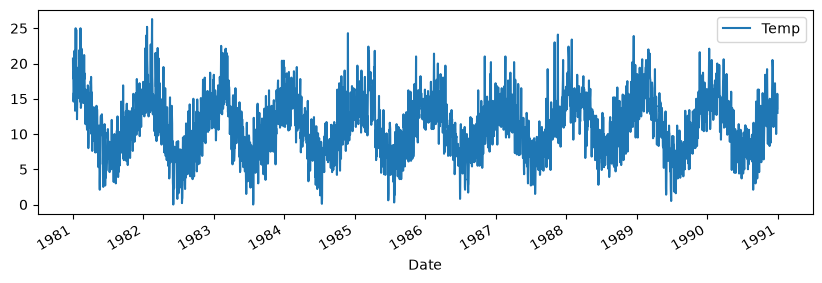

In [3]:
series_ad.plot(figsize=(10,3))
plt.show()

No es estacionaria por lo que no tiene tendencia

In [4]:
serie_ad = series_ad['Temp']

lags_a_probar = [7, 30, 90, 180, 365]
for lag in lags_a_probar:
    coef = serie_ad.autocorr(lag=lag)
    print(f'Coeficiente de correlación (lag={lag}): {coef}')

Coeficiente de correlación (lag=7): 0.5759289535831575
Coeficiente de correlación (lag=30): 0.48252758376323035
Coeficiente de correlación (lag=90): 0.0016188213402442897
Coeficiente de correlación (lag=180): -0.5011909704213942
Coeficiente de correlación (lag=365): 0.5334852661349853


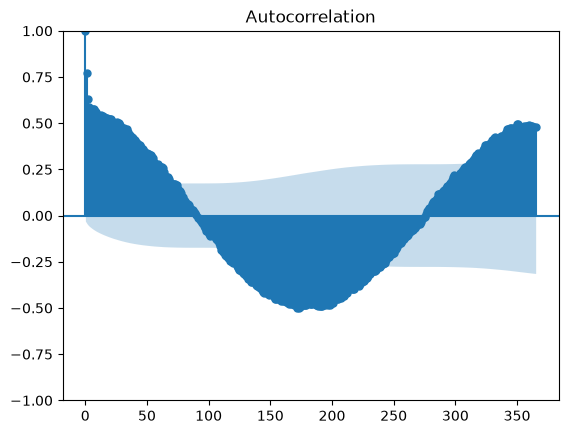

In [5]:
plot_acf(series_ad["Temp"].dropna(), lags=365) 
plt.show()

**Interpretación:** el coeficiente de autocorrelación para lag=365 (un año) es de aproximadamente **0.53**, un valor relativamente alto y claramente superior al de otros desfases arbitrarios. Esto confirma que la serie de temperaturas mínimas diarias tiene un **componente estacional anual** (las temperaturas se repiten de forma similar cada año, con veranos e inviernos marcados). Por eso al descomponerla usaremos `period=365`.

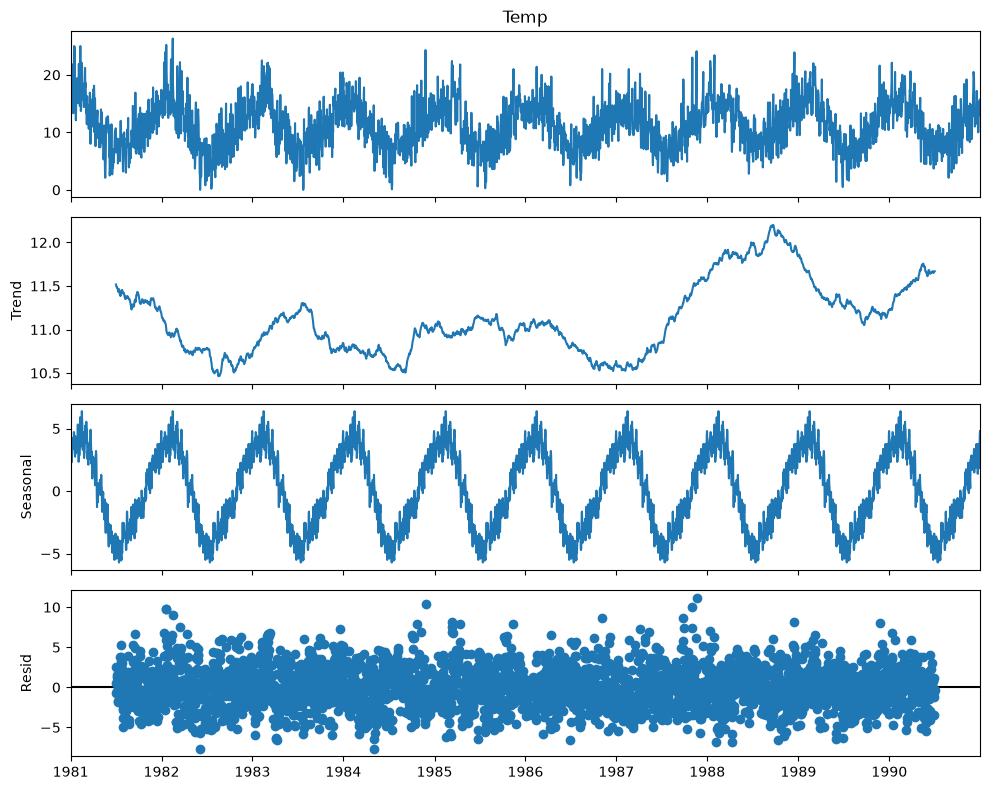

In [6]:
decomposicion_ad = seasonal_decompose(serie_ad, model='additive', period=365)

fig = decomposicion_ad.plot()
fig.set_size_inches(10, 8)
plt.tight_layout()
plt.show()

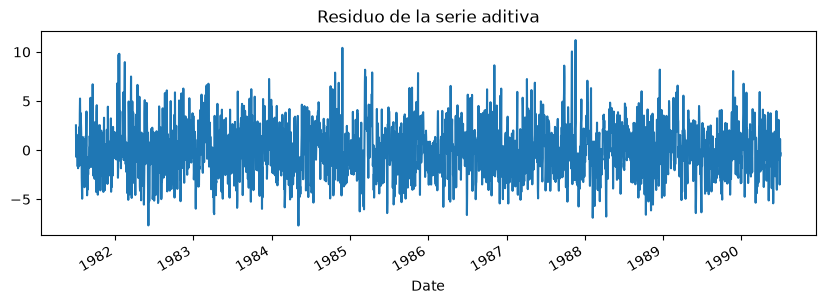

Date
1981-07-02    2.528490
1981-07-03   -0.676707
1981-07-04    0.552060
1981-07-05    1.321162
1981-07-06    1.563932
Name: resid, dtype: float64

In [7]:
##extraer residuo
residuo_ad = decomposicion_ad.resid.dropna()

residuo_ad.plot(figsize=(10,3), title='Residuo de la serie aditiva')
plt.show()

residuo_ad.head()

In [8]:
p_value_adf_hom = adfuller(residuo_ad, autolag='AIC')[1]
p_value_kpss_hom = kpss(residuo_ad)[1]
print("adf p-value para la serie 1", p_value_adf_hom)
print("kpss p-value para la serie 1", p_value_kpss_hom)

adf p-value para la serie 1 2.7078469688982655e-30
kpss p-value para la serie 1 0.1


C:\Users\maren\AppData\Local\Temp\ipykernel_19696\3985031132.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value_adf_hom = adfuller(residuo_ad, autolag='AIC')[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_19696\3985031132.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  p_value_kpss_hom = kpss(residuo_ad)[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_19696\3985031132.py:2: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or 

**Conclusión de estacionariedad (serie aditiva):** el test ADF da un p-valor prácticamente 0 (se rechaza H0, hay estacionariedad) y el test KPSS da un p-valor > 0.05 (no se rechaza H0, también indica estacionariedad). **Ambos test coinciden: el residuo de la serie aditiva es estacionario**, tal y como cabe esperar tras eliminar tendencia y estacionalidad.

In [9]:
lm_test = het_arch(residuo_ad)

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test[0]:.4f}")
print(f"P-valor LM: {lm_test[1]:.4f}")
print(f"Estadístico F: {lm_test[2]:.4f}")
print(f"P-valor F: {lm_test[3]:.4f}")

Resultados del ARCH test:
Estadístico LM: 212.0963
P-valor LM: 0.0000
Estadístico F: 22.6017
P-valor F: 0.0000


c:\Users\maren\.conda\envs\datascience3\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


**Conclusión (serie aditiva):** el p-valor del test de Engle es prácticamente 0, por lo que se rechaza H0 y concluimos que **el residuo presenta heterocedasticidad** (la varianza del residuo no es constante en el tiempo), a pesar de ser una serie estacionaria en media.

### 2. Serie multiplicativa

In [10]:
series_mul = pd.read_csv('airline-passengers.csv', header=0, index_col=0)
series_mul.head()

,Passengers
Month,
1949-01,112
1949-02,118
1949-03,132
1949-04,129
1949-05,121


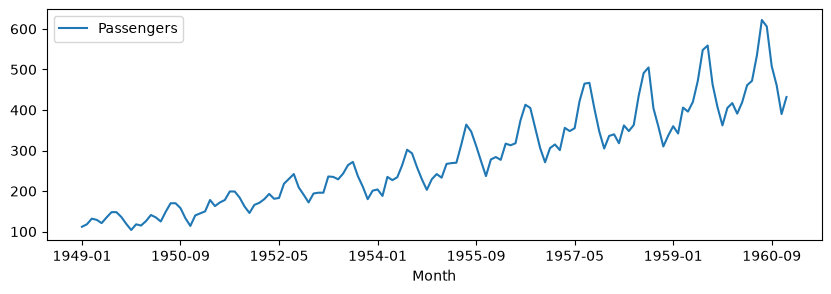

In [11]:
series_mul.plot(figsize=(10,3))
plt.show()

In [12]:
series_mul = series_mul['Passengers']

lags_a_probar = [1, 3, 6, 12, 24]
for lag in lags_a_probar:
    coef = series_mul.autocorr(lag=lag)
    print(f'Coeficiente de correlación (lag={lag}): {coef}')

Coeficiente de correlación (lag=1): 0.9601946480498523
Coeficiente de correlación (lag=3): 0.837394765081794
Coeficiente de correlación (lag=6): 0.7839187959206183
Coeficiente de correlación (lag=12): 0.990527369208544
Coeficiente de correlación (lag=24): 0.9832540581084245


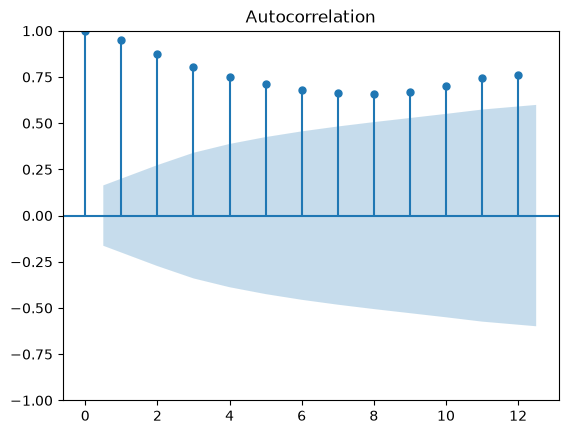

In [20]:
plot_acf(series_mul.reset_index()['Passengers'].dropna(), lags=12) 
plt.show()

**Interpretación:** el coeficiente de autocorrelación para lag=12 (un año) es de aproximadamente **0.99**, muy superior al resto de desfases y muy próximo a 1. Esto evidencia un **componente estacional anual muy marcado** en el número de pasajeros (patrones que se repiten cada 12 meses), además de una fuerte tendencia creciente. Usaremos por tanto `period=12` en la descomposición.

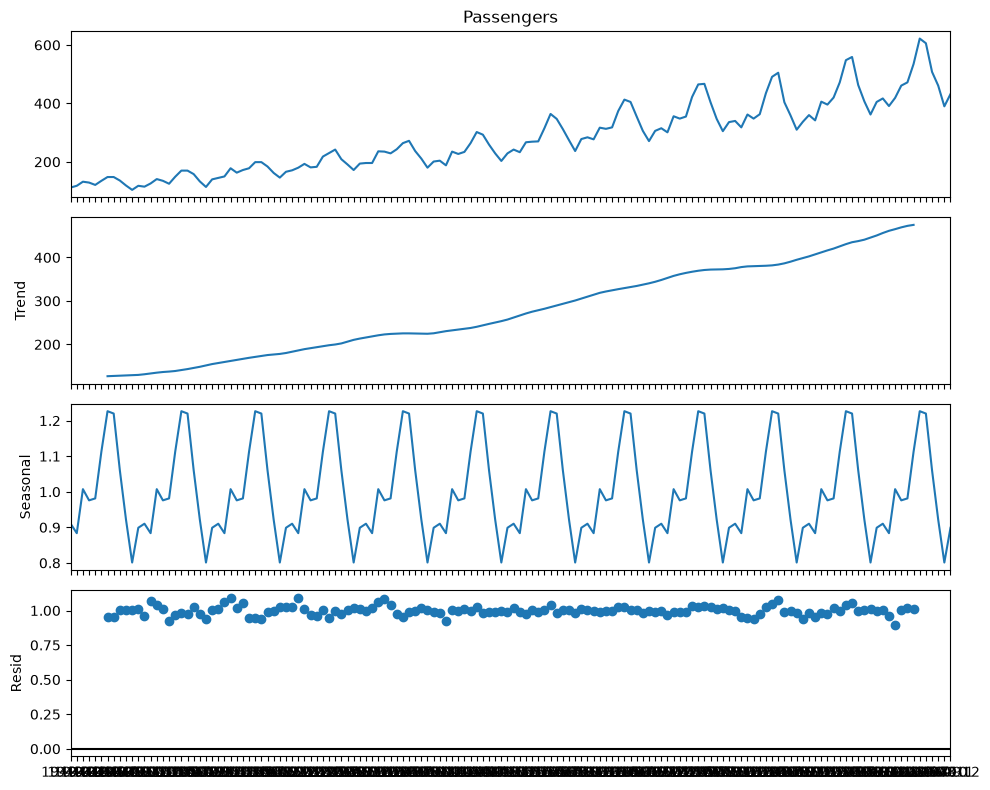

In [21]:
decomposicion_mul = seasonal_decompose(series_mul, model='multiplicative', period=12)

fig = decomposicion_mul.plot()
fig.set_size_inches(10, 8)
plt.tight_layout()
plt.show()

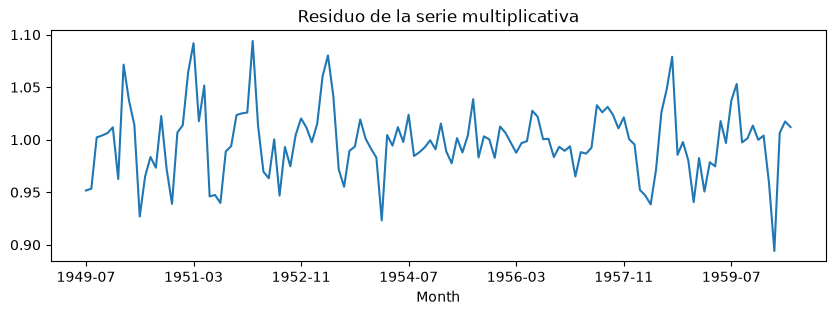

Month
1949-07    0.951664
1949-08    0.953401
1949-09    1.002220
1949-10    1.004028
1949-11    1.006270
Name: resid, dtype: float64

In [22]:
residuo_mul = decomposicion_mul.resid.dropna()

residuo_mul.plot(figsize=(10,3), title='Residuo de la serie multiplicativa')
plt.show()

residuo_mul.head()

In [23]:
p_value_adf_hom = adfuller(residuo_ad, autolag='AIC')[1]
p_value_kpss_hom = kpss(residuo_ad)[1]
print("adf p-value para la serie 1", p_value_adf_hom)
print("kpss p-value para la serie 1", p_value_kpss_hom)

adf p-value para la serie 1 2.7078469688982655e-30
kpss p-value para la serie 1 0.1


C:\Users\maren\AppData\Local\Temp\ipykernel_19696\3985031132.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value_adf_hom = adfuller(residuo_ad, autolag='AIC')[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_19696\3985031132.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  p_value_kpss_hom = kpss(residuo_ad)[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_19696\3985031132.py:2: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or 

**Conclusión de estacionariedad (serie multiplicativa):** el ADF da un p-valor muy pequeño (rechaza H0: hay estacionariedad) y el KPSS da un p-valor > 0.05 (no rechaza H0: también indica estacionariedad). **Ambos test coinciden en que el residuo es estacionario**, aunque al tratarse de una muestra mucho más pequeña (132 datos) la conclusión es algo menos robusta que en la serie aditiva.

In [24]:
lm_test = het_arch(residuo_ad)

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test[0]:.4f}")
print(f"P-valor LM: {lm_test[1]:.4f}")
print(f"Estadístico F: {lm_test[2]:.4f}")
print(f"P-valor F: {lm_test[3]:.4f}")

Resultados del ARCH test:
Estadístico LM: 212.0963
P-valor LM: 0.0000
Estadístico F: 22.6017
P-valor F: 0.0000


c:\Users\maren\.conda\envs\datascience3\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


**Conclusión (serie multiplicativa):** el p-valor del test de Engle es muy pequeño (≈6·10⁻⁷), por lo que se rechaza H0 y concluimos que **el residuo también presenta heterocedasticidad**. Esto es coherente con el hecho de que sea una serie multiplicativa: la amplitud de las variaciones crece junto con el nivel de la serie (más pasajeros -> más dispersión), lo que se traduce en varianza no constante incluso después de extraer tendencia y estacionalidad.